# 02 · Árvore, Random Forest e XGBoost prevendo a rede 12 minutos à frente

**Pergunta do experimento:** para um preditor de degradação de rede (OK, RISCO ou FALHA daqui a 12 minutos),
qual dos três modelos é o mais adequado, considerando **acerto**, **custo dos erros**, **tempo** e **interpretabilidade**?
E algum deles vence a regra mais simples, **repetir a classe de agora**?

Regras que seguimos para a comparação ser justa:

1. Os três modelos usam **os mesmos dados**, a **mesma divisão no tempo** e a **mesma semente**.
2. Cada modelo recebe o **mesmo esforço de ajuste**: o mesmo número de combinações de hiperparâmetros.
3. O ajuste usa só a **validação**. O **teste** é usado **uma única vez**, no final.

## 1. Bibliotecas e dados

In [1]:
# Instala tudo o que o projeto usa no MESMO Python do notebook (funciona no Colab e no computador)
%pip install -q xgboost pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

SEMENTE = 42          # semente fixa: todo mundo que rodar obtém os mesmos números
np.random.seed(SEMENTE)

# Pasta raiz do projeto: funciona rodando de dentro de notebooks/ ou no Colab
RAIZ = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
n = lambda v: f"{int(v):,}".replace(",", ".")   # número com ponto de milhar, como no Brasil
DADOS = os.path.join(RAIZ, "dados")
IMG = os.path.join(RAIZ, "img")
RESULTADOS = os.path.join(RAIZ, "resultados")
for pasta in (DADOS, IMG, RESULTADOS):
    os.makedirs(pasta, exist_ok=True)

import xgboost
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

VERSOES = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
           "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__}
print(VERSOES)

{'python': '3.14.7', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1'}


In [3]:
# Paleta visual do projeto (a mesma da página): Cotton, Cherry Red, Maroon, Noir Black e um neutro
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

COTTON, CHERRY, MAROON, NOIR, NEUTRO = "#EDEBDD", "#810100", "#630000", "#1B1717", "#8C8475"
AREIA = "#C9BFA8"     # cor extra para a persistência (a regra de comparação)
FUNDO = "#F6F4EA"     # fundo das figuras, igual ao das caixas da página

plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[CHERRY, NOIR, NEUTRO, AREIA]),   # Árvore, Random Forest, XGBoost, persistência
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": NOIR, "axes.labelcolor": NOIR, "text.color": NOIR,
    "xtick.color": NOIR, "ytick.color": NOIR, "grid.color": "#D8D3C2",
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
})
MAPA_CONFUSAO = LinearSegmentedColormap.from_list("cotton_maroon", [COTTON, "#DDA59C", "#A8322B", MAROON])
CORES_CLASSE = {"OK": "#4F6F52", "RISCO": "#B8860B", "FALHA": CHERRY}

In [4]:
ATRIBUTOS = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct", "timeout_atual",
             "n5_timeout", "n5_aumento80", "n5_risco"]
CLASSES = ["OK", "RISCO", "FALHA"]
CODIGO = {c: i for i, c in enumerate(CLASSES)}       # o XGBoost quer classes numeradas 0, 1, 2

dados = pd.read_csv(os.path.join(DADOS, "dataset_artigo.csv.gz"), parse_dates=["timestamp"])
partes = {b: dados[dados["bloco"] == b].reset_index(drop=True) for b in ["treino", "validacao", "teste"]}
X_treino, X_val, X_teste = (partes[b][ATRIBUTOS] for b in ["treino", "validacao", "teste"])
y_treino, y_val, y_teste = (partes[b]["classe_futura"].map(CODIGO).to_numpy() for b in ["treino", "validacao", "teste"])

for nome, X, y in [("treino", X_treino, y_treino), ("validação", X_val, y_val), ("teste", X_teste, y_teste)]:
    print(f"{nome:10s} {len(y):7d} linhas | FALHA {np.mean(y == 2):.1%} | RISCO {np.mean(y == 1):.1%}")

treino      115183 linhas | FALHA 11.0% | RISCO 6.5%
validação    45227 linhas | FALHA 13.8% | RISCO 8.1%
teste        66702 linhas | FALHA 14.3% | RISCO 7.6%


## 2. Como vamos medir

Três classes, e a mais comum (OK) é quase 80% das linhas. Por isso:

| Métrica | Pergunta que responde | Em redes |
|---|---|---|
| **F1 macro** | Média do F1 das três classes, com o mesmo peso para cada uma | Não deixa a classe OK esconder os erros em RISCO e FALHA. É a métrica principal |
| **Recall de FALHA** | Das falhas que vieram, quantas o modelo anunciou? | Falha não anunciada = enlace degradando sem ninguém investigar (o erro mais caro) |
| **Precisão de FALHA** | Dos alarmes de FALHA, quantos eram FALHA mesmo? | Precisão baixa = **alarme falso** e equipe cansada |
| **Recall de início de FALHA** | Quando o fluxo **ainda não** está em FALHA e vai entrar, o modelo avisa antes? | É o que a persistência nunca acerta: o ganho real de um preditor |
| **Matriz de confusão** | Contagem de acertos e de cada troca de classe | Mostra *onde* o modelo erra |

In [5]:
def avaliar(y_verdadeiro, y_previsto, classe_atual):
    p, r, f, _ = precision_recall_fscore_support(y_verdadeiro, y_previsto, labels=[0, 1, 2], zero_division=0)
    inicio = (y_verdadeiro == 2) & (classe_atual != "FALHA")
    return {
        "F1 macro": f1_score(y_verdadeiro, y_previsto, average="macro"),
        "acurácia": accuracy_score(y_verdadeiro, y_previsto),
        "precisão FALHA": p[2], "recall FALHA": r[2], "F1 FALHA": f[2],
        "recall RISCO": r[1], "F1 RISCO": f[1],
        "recall início FALHA": float(np.mean(y_previsto[inicio] == 2)) if inicio.any() else np.nan,
    }

def persistencia(parte):
    """A regra de comparação: a classe daqui a 12 minutos é a classe de agora."""
    return parte["classe_atual"].map(CODIGO).to_numpy()

## 3. As duas regras de comparação, na validação

Antes de treinar qualquer modelo, vemos quanto valem duas regras sem aprendizado:
**sempre OK** (a classe mais comum) e a **persistência** (repetir a classe de agora).

In [6]:
base_val = pd.DataFrame({
    "sempre OK": avaliar(y_val, np.zeros_like(y_val), partes["validacao"]["classe_atual"]),
    "persistência": avaliar(y_val, persistencia(partes["validacao"]), partes["validacao"]["classe_atual"]),
}).T
base_val.round(4)

,F1 macro,acurácia,precisão FALHA,recall FALHA,F1 FALHA,recall RISCO,F1 RISCO,recall início FALHA
sempre OK,0.2924,0.7812,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
persistência,0.7129,0.8578,0.7433,0.7409,0.7421,0.4781,0.4791,0.0


## 4. Uma árvore pequena em ação (exemplo para o artigo)

Antes de comparar, treinamos uma árvore **rasa** (profundidade 3) só para enxergar como ela decide
o futuro do fluxo. Cada caixa é uma pergunta sobre um atributo, e as folhas dão a classe prevista.

|--- z_robusto <= 3.43
|   |--- n5_risco <= 3.50
|   |   |--- n5_risco <= 1.50
|   |   |   |--- class: OK
|   |   |--- n5_risco >  1.50
|   |   |   |--- class: OK
|   |--- n5_risco >  3.50
|   |   |--- n5_risco <= 4.50
|   |   |   |--- class: OK
|   |   |--- n5_risco >  4.50
|   |   |   |--- class: RISCO
|--- z_robusto >  3.43
|   |--- jitter_relativo <= 2.68
|   |   |--- z_robusto <= 9.30
|   |   |   |--- class: FALHA
|   |   |--- z_robusto >  9.30
|   |   |   |--- class: FALHA
|   |--- jitter_relativo >  2.68
|   |   |--- n5_risco <= 3.50
|   |   |   |--- class: OK
|   |   |--- n5_risco >  3.50
|   |   |   |--- class: FALHA

F1 macro na validação: 0.711


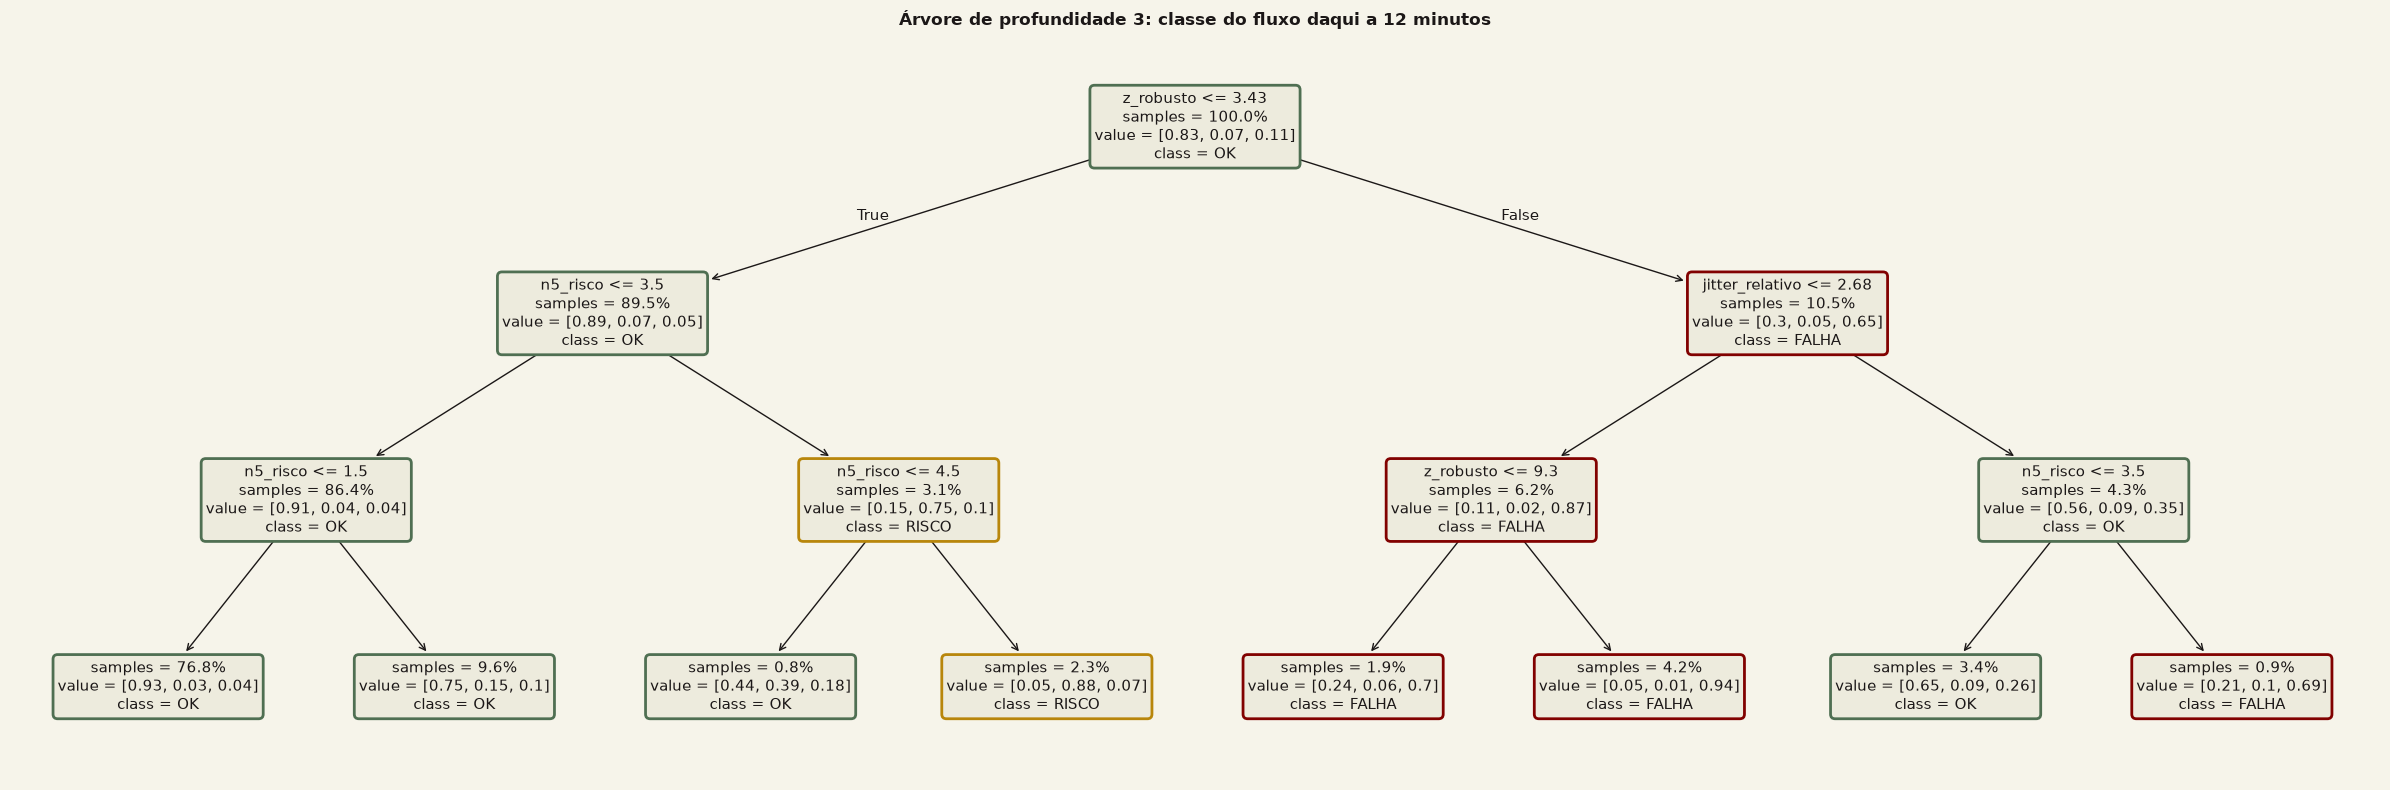

In [7]:
arvore_pequena = DecisionTreeClassifier(max_depth=3, random_state=SEMENTE).fit(X_treino, y_treino)
print(export_text(arvore_pequena, feature_names=ATRIBUTOS, class_names=CLASSES, decimals=2))
print(f"F1 macro na validação: {f1_score(y_val, arvore_pequena.predict(X_val), average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(24, 8))
caixas = plot_tree(arvore_pequena, feature_names=ATRIBUTOS, class_names=CLASSES, filled=False, rounded=True,
                   impurity=False, proportion=True, precision=2, fontsize=11, ax=ax)
for caixa in caixas:   # pinta as caixas pela classe prevista
    fundo = caixa.get_bbox_patch()
    if fundo is not None:
        texto = caixa.get_text()
        cor = next((CORES_CLASSE[c] for c in CLASSES if f"class = {c}" in texto), NOIR)
        fundo.set_facecolor(COTTON)
        fundo.set_edgecolor(cor)
        fundo.set_linewidth(2)
ax.set_title("Árvore de profundidade 3: classe do fluxo daqui a 12 minutos")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "arvore_profundidade3.png"), dpi=150); plt.show()

## 5. Overfitting: o que acontece quando a árvore cresce?

Uma árvore muito profunda decora o treino (**overfitting**): acerta muito nos dados que já viu e piora nos dados novos.
Medimos o F1 macro no treino e na validação variando a profundidade.

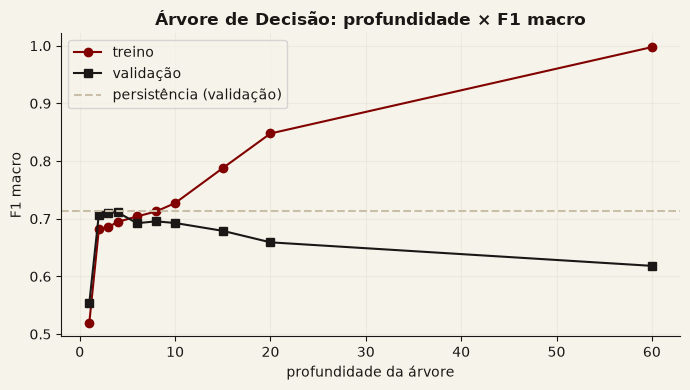

,profundidade,profundidade_real,F1 treino,F1 validação
0,1,1,0.5197,0.5536
1,2,2,0.6815,0.7073
2,3,3,0.6858,0.7107
3,4,4,0.6946,0.7108
4,6,6,0.7039,0.6922
5,8,8,0.7126,0.6955
6,10,10,0.7271,0.6926
7,15,15,0.7878,0.6790
8,20,20,0.8478,0.6591
9,sem limite,60,0.9975,0.6183


In [8]:
profundidades = [1, 2, 3, 4, 6, 8, 10, 15, 20, None]
linhas = []
for p in profundidades:
    m = DecisionTreeClassifier(max_depth=p, random_state=SEMENTE).fit(X_treino, y_treino)
    linhas.append({"profundidade": "sem limite" if p is None else p, "profundidade_real": m.get_depth(),
                   "F1 treino": f1_score(y_treino, m.predict(X_treino), average="macro"),
                   "F1 validação": f1_score(y_val, m.predict(X_val), average="macro")})
curva_prof = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva_prof["profundidade_real"], curva_prof["F1 treino"], "o-", label="treino")
ax.plot(curva_prof["profundidade_real"], curva_prof["F1 validação"], "s-", label="validação")
ax.axhline(base_val.loc["persistência", "F1 macro"], ls="--", color=AREIA, label="persistência (validação)")
ax.set_xlabel("profundidade da árvore"); ax.set_ylabel("F1 macro"); ax.grid(alpha=.3); ax.legend()
ax.set_title("Árvore de Decisão: profundidade × F1 macro")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "overfitting_profundidade.png"), dpi=150); plt.show()
curva_prof.round(4)

## 6. Ajuste de hiperparâmetros com o mesmo esforço para os três

**Hiperparâmetro** é uma configuração escolhida antes do treino (ex.: profundidade máxima, número de árvores).
Para cada modelo, sorteamos **o mesmo número de combinações** (`N_TENTATIVAS`), treinamos cada uma no **treino**
e ficamos com a de maior **F1 macro na validação**.

Os três podem testar dar **mais peso às classes raras** (`class_weight="balanced"` na árvore e na floresta,
pesos por amostra no XGBoost), porque RISCO e FALHA são minoria.
No XGBoost usamos **early stopping**: ele para de adicionar árvores quando o erro na validação deixa de cair por 30 rodadas.

In [9]:
N_TENTATIVAS = 12

ESPACOS = {
    "Árvore de Decisão": {
        "max_depth": [4, 6, 8, 10, 12, 16, None],
        "min_samples_leaf": [1, 5, 10, 20, 50],
        "criterion": ["gini", "entropy"],
        "ccp_alpha": [0.0, 1e-5, 1e-4],             # poda
        "class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [8, 12, 20, None],
        "max_features": ["sqrt", 0.5, 1.0],
        "min_samples_leaf": [1, 5, 10],
        "class_weight": [None, "balanced"],
    },
    "XGBoost": {
        "learning_rate": [0.03, 0.05, 0.1, 0.2],
        "max_depth": [3, 4, 6, 8],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0.1, 1.0, 5.0],               # regularização L2
        "min_child_weight": [1, 3, 5],
        "pesos_classes": [False, True],
    },
}

def criar_modelo(nome, params):
    if nome == "Árvore de Decisão":
        return DecisionTreeClassifier(random_state=SEMENTE, **params)
    if nome == "Random Forest":
        return RandomForestClassifier(random_state=SEMENTE, n_jobs=-1, **params)
    if nome == "XGBoost":
        params = {k: v for k, v in params.items() if k != "pesos_classes"}
        return XGBClassifier(n_estimators=1000, early_stopping_rounds=30, eval_metric="mlogloss",
                             objective="multi:softprob", tree_method="hist", random_state=SEMENTE,
                             n_jobs=-1, **params)

def treinar(nome, modelo, params):
    if nome == "XGBoost":   # early stopping olha a validação, nunca o teste
        pesos = compute_sample_weight("balanced", y_treino) if params.get("pesos_classes") else None
        modelo.fit(X_treino, y_treino, sample_weight=pesos, eval_set=[(X_val, y_val)], verbose=False)
    else:
        modelo.fit(X_treino, y_treino)
    return modelo

In [10]:
historico, melhores = [], {}

for nome, espaco in ESPACOS.items():
    combinacoes = list(ParameterSampler(espaco, n_iter=N_TENTATIVAS, random_state=SEMENTE))
    t_ajuste = time.perf_counter()
    melhor_f1 = -1
    for i, params in enumerate(combinacoes, 1):
        t0 = time.perf_counter()
        modelo = treinar(nome, criar_modelo(nome, params), params)
        t_treino = time.perf_counter() - t0
        f1_val = f1_score(y_val, modelo.predict(X_val), average="macro")
        historico.append({"modelo": nome, "tentativa": i, "F1 macro validação": f1_val,
                          "tempo treino (s)": t_treino, **params})
        if f1_val > melhor_f1:
            melhor_f1 = f1_val
            melhores[nome] = {"modelo": modelo, "params": params, "tempo_treino": t_treino}
    print(f"{nome:18s} melhor F1 macro val = {melhor_f1:.4f} | ajuste total {time.perf_counter()-t_ajuste:6.1f}s"
          f" | {melhores[nome]['params']}")

historico = pd.DataFrame(historico)
historico.to_csv(os.path.join(RESULTADOS, "historico_ajuste.csv"), index=False)

Árvore de Decisão  melhor F1 macro val = 0.7153 | ajuste total    6.9s | {'min_samples_leaf': 1, 'max_depth': 4, 'criterion': 'entropy', 'class_weight': None, 'ccp_alpha': 1e-05}


Random Forest      melhor F1 macro val = 0.7159 | ajuste total   42.8s | {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None}


XGBoost            melhor F1 macro val = 0.7232 | ajuste total   99.7s | {'subsample': 0.85, 'reg_lambda': 1.0, 'pesos_classes': False, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [11]:
# Quantas árvores o early stopping escolheu no melhor XGBoost?
xgb_melhor = melhores["XGBoost"]["modelo"]
print("Rodadas usadas pelo XGBoost:", xgb_melhor.best_iteration + 1, "de 1000 possíveis")

Rodadas usadas pelo XGBoost: 452 de 1000 possíveis


## 7. Avaliação final no conjunto de teste (uma única vez)

Para cada modelo vencedor e para as duas regras de comparação medimos as métricas e três tempos:

- **treino**: quanto demorou para treinar a configuração escolhida;
- **predição em lote**: classificar todas as medições do teste de uma vez;
- **latência por medição**: classificar **uma** medição por vez, como faria um monitor a cada novo ping.

In [12]:
def tempo_lote(modelo, X, repeticoes=5):
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); modelo.predict(X); tempos.append(time.perf_counter() - t0)
    return float(np.median(tempos))

def latencia_uma(modelo, X, repeticoes=200):
    linha = X.iloc[[0]]
    modelo.predict(linha)    # aquecimento
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); modelo.predict(linha); tempos.append(time.perf_counter() - t0)
    return float(np.median(tempos))

atual_teste = partes["teste"]["classe_atual"]
previsoes = {nome: info["modelo"].predict(X_teste) for nome, info in melhores.items()}
previsoes["Persistência"] = persistencia(partes["teste"])

resultados = []
for nome, y_prev in previsoes.items():
    linha = {"modelo": nome, **avaliar(y_teste, y_prev, atual_teste)}
    cm = confusion_matrix(y_teste, y_prev, labels=[0, 1, 2])
    linha["FALHA perdidas (FN)"] = int(cm[2, 0] + cm[2, 1])
    linha["alarmes falsos de FALHA (FP)"] = int(cm[0, 2] + cm[1, 2])
    if nome in melhores:
        m = melhores[nome]["modelo"]
        linha.update({"treino (s)": melhores[nome]["tempo_treino"],
                      "predição lote (s)": tempo_lote(m, X_teste),
                      "latência 1 medição (ms)": 1000 * latencia_uma(m, X_teste)})
    resultados.append(linha)

resultados = pd.DataFrame(resultados).set_index("modelo")
resultados.to_csv(os.path.join(RESULTADOS, "metricas_teste.csv"))
resultados.round(4)

,F1 macro,acurácia,precisão FALHA,recall FALHA,F1 FALHA,recall RISCO,F1 RISCO,recall início FALHA,FALHA perdidas (FN),alarmes falsos de FALHA (FP),treino (s),predição lote (s),latência 1 medição (ms)
modelo,,,,,,,,,,,,,
Árvore de Decisão,0.7590,0.9021,0.9128,0.7112,0.7995,0.3764,0.5357,0.0020,2763,650,0.3071,0.0057,0.5627
Random Forest,0.7628,0.9033,0.9374,0.6981,0.8002,0.3874,0.5457,0.0015,2888,446,1.3346,0.0717,15.7229
XGBoost,0.7645,0.9032,0.9373,0.6965,0.7992,0.3971,0.5518,0.0020,2903,446,7.2140,0.2428,1.5284
Persistência,0.7533,0.8785,0.7905,0.7920,0.7912,0.5410,0.5413,0.0000,1990,2008,NaN,NaN,NaN


## 8. Matrizes de confusão

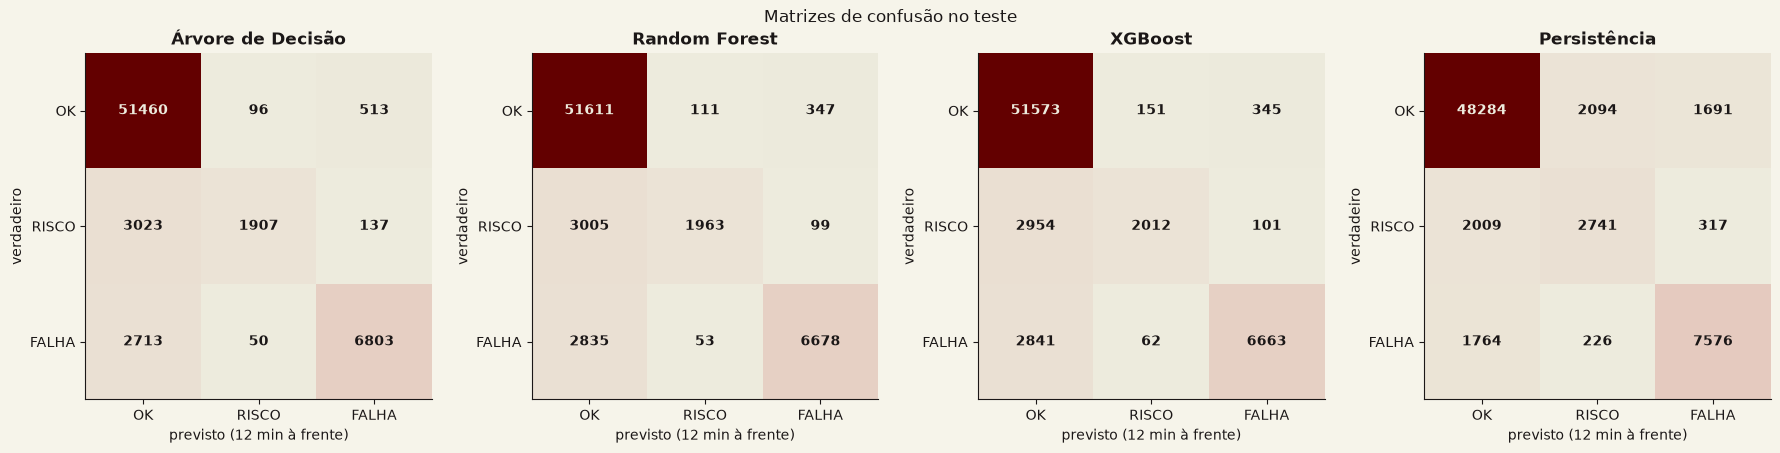

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (nome, y_prev) in zip(axes, previsoes.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix(y_teste, y_prev, labels=[0, 1, 2]),
                                  display_labels=CLASSES).plot(ax=ax, colorbar=False, values_format="d", cmap=MAPA_CONFUSAO)
    for (i, j), texto in np.ndenumerate(disp.text_):   # texto claro em fundo escuro e vice-versa
        r, g, b, _ = MAPA_CONFUSAO(disp.im_.norm(disp.confusion_matrix[i, j]))
        texto.set_color(NOIR if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.45 else COTTON)
        texto.set_fontweight("bold")
    ax.set_title(nome); ax.set_xlabel("previsto (12 min à frente)"); ax.set_ylabel("verdadeiro")
plt.suptitle("Matrizes de confusão no teste")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "matrizes_confusao.png"), dpi=150); plt.show()

## 9. Gráfico das métricas

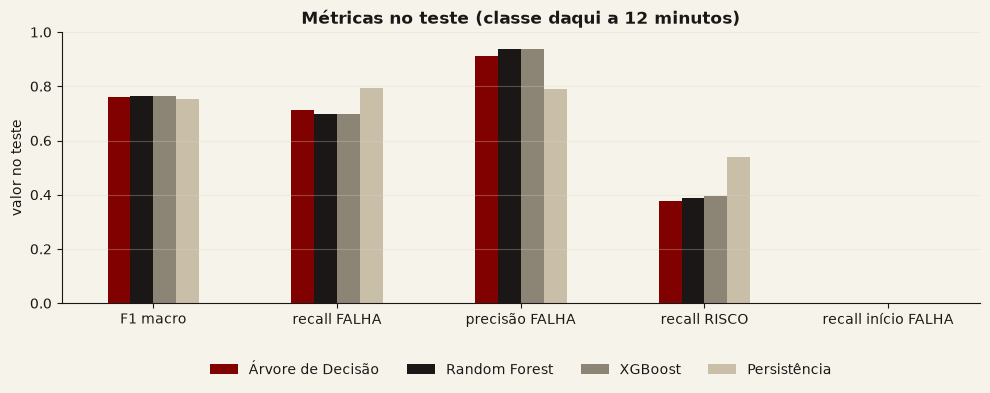

In [14]:
colunas = ["F1 macro", "recall FALHA", "precisão FALHA", "recall RISCO", "recall início FALHA"]
ax = resultados[colunas].T.plot.bar(rot=0, figsize=(10, 4.2))
ax.set_ylim(0, 1); ax.set_ylabel("valor no teste"); ax.grid(axis="y", alpha=.3)
ax.set_title("Métricas no teste (classe daqui a 12 minutos)")
ax.legend(title="", ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "metricas_teste.png"), dpi=150); plt.show()

## 10. Os modelos aprenderam geografia?

Um bom preditor deve funcionar igual em caminhos curtos e longos. Separamos o F1 macro do teste
pelos três grupos de RTT normal criados no notebook 01 (essa coluna nunca entrou nos modelos).

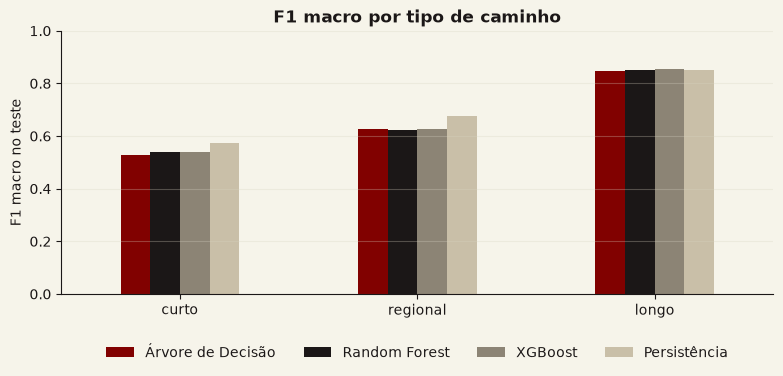

,Árvore de Decisão,Random Forest,XGBoost,Persistência,nº no teste
curto,0.529,0.540,0.541,0.575,22682
regional,0.628,0.621,0.628,0.677,22028
longo,0.849,0.852,0.854,0.852,21992


In [15]:
escopo = partes["teste"]["escopo"].to_numpy()
por_escopo = {}
for nome, y_prev in previsoes.items():
    por_escopo[nome] = {e: f1_score(y_teste[escopo == e], y_prev[escopo == e], average="macro")
                        for e in ["curto", "regional", "longo"]}
por_escopo = pd.DataFrame(por_escopo)
por_escopo["nº no teste"] = [int((escopo == e).sum()) for e in por_escopo.index]
por_escopo.to_csv(os.path.join(RESULTADOS, "f1_por_escopo.csv"))

ax = por_escopo.drop(columns="nº no teste").plot.bar(rot=0, figsize=(8, 4))
ax.set_ylim(0, 1); ax.set_ylabel("F1 macro no teste"); ax.grid(axis="y", alpha=.3)
ax.set_title("F1 macro por tipo de caminho")
ax.legend(title="", ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.3), frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "f1_por_escopo.png"), dpi=150); plt.show()
por_escopo.round(3)

## 11. Interpretabilidade: quais atributos mais pesam?

- A **árvore** pode ser lida inteira, pergunta por pergunta.
- **Random Forest** e **XGBoost** não podem ser lidos árvore por árvore, mas mostram a
  **importância dos atributos**: quanto cada atributo ajudou a separar as classes.

Melhor árvore: profundidade 4, 16 folhas


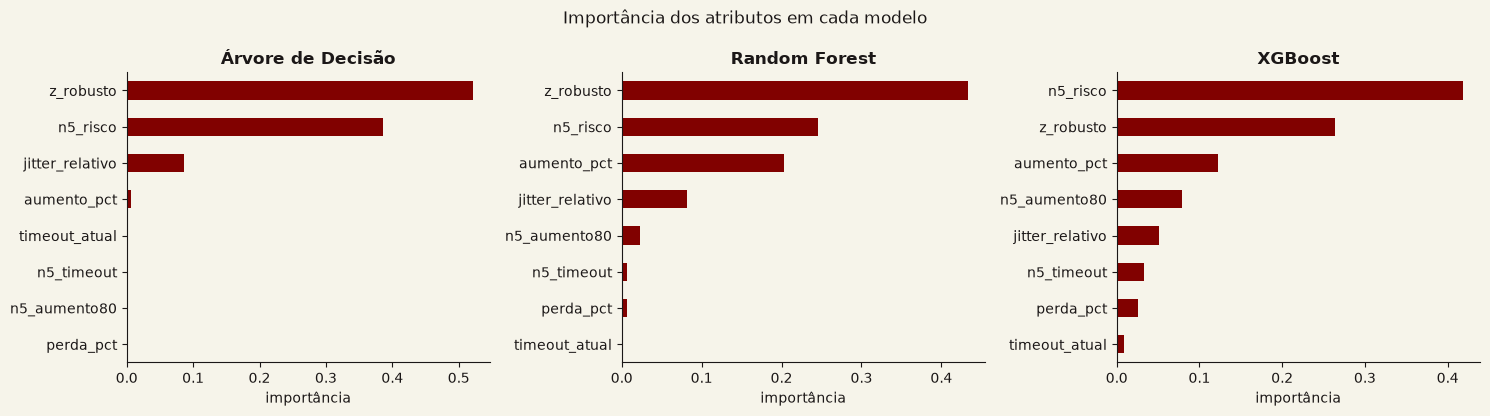

In [16]:
arv = melhores["Árvore de Decisão"]["modelo"]
print(f"Melhor árvore: profundidade {arv.get_depth()}, {arv.get_n_leaves()} folhas")
with open(os.path.join(RESULTADOS, "arvore_escolhida.txt"), "w", encoding="utf-8") as f:
    f.write(export_text(arv, feature_names=ATRIBUTOS, class_names=CLASSES, decimals=3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, nome in zip(axes, melhores):
    imp = pd.Series(melhores[nome]["modelo"].feature_importances_, index=ATRIBUTOS)
    imp.sort_values().plot.barh(ax=ax)
    ax.set_title(nome); ax.set_xlabel("importância")
plt.suptitle("Importância dos atributos em cada modelo")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "importancia_atributos.png"), dpi=150); plt.show()

## 12. Experimentos extras (para as figuras do artigo)

### 12a. Random Forest: o que muda com mais árvores?

Com poucas árvores o resultado oscila; com mais árvores a votação fica estável.
É a **redução de variância** do bagging na prática.

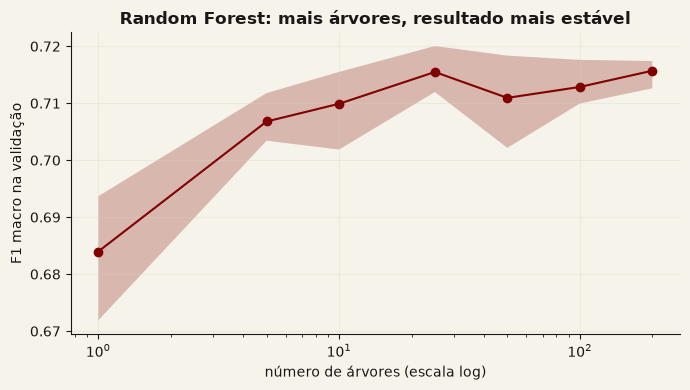

,árvores,F1 médio,F1 mín,F1 máx
0,1,0.6840,0.6719,0.6937
1,5,0.7068,0.7034,0.7118
2,10,0.7099,0.7019,0.7155
3,25,0.7155,0.7120,0.7200
4,50,0.7109,0.7022,0.7184
5,100,0.7129,0.7099,0.7176
6,200,0.7157,0.7126,0.7174


In [17]:
params_rf = {k: v for k, v in melhores["Random Forest"]["params"].items() if k != "n_estimators"}
n_arvores = [1, 5, 10, 25, 50, 100, 200]
curva_rf = []
for n in n_arvores:
    f1s = []
    for semente in range(3):   # 3 sementes diferentes para ver a oscilação
        m = RandomForestClassifier(n_estimators=n, random_state=semente, n_jobs=-1, **params_rf)
        f1s.append(f1_score(y_val, m.fit(X_treino, y_treino).predict(X_val), average="macro"))
    curva_rf.append({"árvores": n, "F1 médio": np.mean(f1s), "F1 mín": min(f1s), "F1 máx": max(f1s)})
curva_rf = pd.DataFrame(curva_rf)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva_rf["árvores"], curva_rf["F1 médio"], "o-")
ax.fill_between(curva_rf["árvores"], curva_rf["F1 mín"], curva_rf["F1 máx"], alpha=.25)
ax.set_xscale("log"); ax.set_xlabel("número de árvores (escala log)"); ax.set_ylabel("F1 macro na validação")
ax.set_title("Random Forest: mais árvores, resultado mais estável"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "rf_numero_arvores.png"), dpi=150); plt.show()
curva_rf.round(4)

### 12b. XGBoost: taxa de aprendizado e early stopping

Cada nova árvore corrige um pouco dos erros das anteriores (**redução de viés**).
A **taxa de aprendizado** controla o tamanho desse passo.

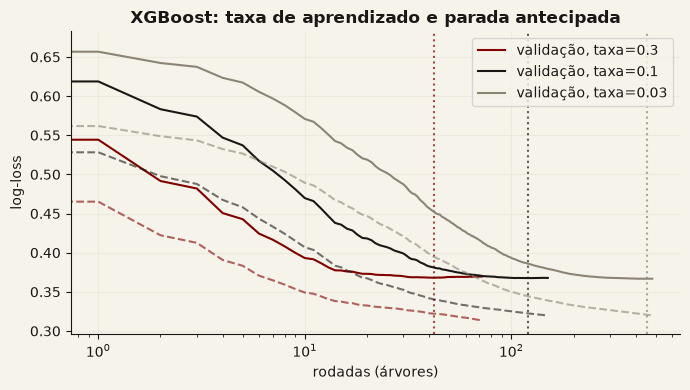

In [18]:
params_xgb = {k: v for k, v in melhores["XGBoost"]["params"].items() if k not in ("learning_rate", "pesos_classes")}
pesos = compute_sample_weight("balanced", y_treino) if melhores["XGBoost"]["params"].get("pesos_classes") else None
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.3, 0.1, 0.03]:
    m = XGBClassifier(n_estimators=1000, learning_rate=lr, early_stopping_rounds=30, eval_metric="mlogloss",
                      objective="multi:softprob", tree_method="hist", random_state=SEMENTE, n_jobs=-1, **params_xgb)
    m.fit(X_treino, y_treino, sample_weight=pesos, eval_set=[(X_treino, y_treino), (X_val, y_val)], verbose=False)
    hist = m.evals_result()
    linha, = ax.plot(hist["validation_1"]["mlogloss"], label=f"validação, taxa={lr}")
    ax.plot(hist["validation_0"]["mlogloss"], "--", color=linha.get_color(), alpha=.6)
    ax.axvline(m.best_iteration, color=linha.get_color(), ls=":", alpha=.7)
ax.set_xlabel("rodadas (árvores)"); ax.set_ylabel("log-loss"); ax.set_xscale("log")
ax.set_title("XGBoost: taxa de aprendizado e parada antecipada"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(IMG, "xgb_taxa_aprendizado.png"), dpi=150); plt.show()

## 13. Salvar o resumo para a página e o README

In [19]:
resumo = {
    "versoes": VERSOES,
    "semente": SEMENTE,
    "n_tentativas_por_modelo": N_TENTATIVAS,
    "tamanhos": {"treino": int(len(y_treino)), "validacao": int(len(y_val)), "teste": int(len(y_teste))},
    "melhores_hiperparametros": {n: i["params"] for n, i in melhores.items()},
    "arvore_escolhida": {"profundidade": int(arv.get_depth()), "folhas": int(arv.get_n_leaves())},
    "xgboost_rodadas": int(xgb_melhor.best_iteration + 1),
    "persistencia_validacao": base_val.loc["persistência"].to_dict(),
}
with open(os.path.join(RESULTADOS, "resumo_experimento.json"), "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2, default=str)

# Tabela pronta para colar na página (HTML)
resultados.round(4).to_html(os.path.join(RESULTADOS, "tabela_metricas.html"))
print(json.dumps(resumo, ensure_ascii=False, indent=2, default=str))

{
  "versoes": {
    "python": "3.14.7",
    "numpy": "2.5.4",
    "pandas": "3.0.6",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1"
  },
  "semente": 42,
  "n_tentativas_por_modelo": 12,
  "tamanhos": {
    "treino": 115183,
    "validacao": 45227,
    "teste": 66702
  },
  "melhores_hiperparametros": {
    "Árvore de Decisão": {
      "min_samples_leaf": 1,
      "max_depth": 4,
      "criterion": "entropy",
      "class_weight": null,
      "ccp_alpha": 1e-05
    },
    "Random Forest": {
      "n_estimators": 100,
      "min_samples_leaf": 5,
      "max_features": "sqrt",
      "max_depth": 12,
      "class_weight": null
    },
    "XGBoost": {
      "subsample": 0.85,
      "reg_lambda": 1.0,
      "pesos_classes": false,
      "min_child_weight": 3,
      "max_depth": 6,
      "learning_rate": 0.03,
      "colsample_bytree": 0.6
    }
  },
  "arvore_escolhida": {
    "profundidade": 4,
    "folhas": 16
  },
  "xgboost_rodadas": 452,
  "persistencia_validacao": {
    "F1 macr

## 14. Perguntas para escrever a recomendação

Não existe resposta certa. Usem **os números acima** para responder:

1. Algum modelo vence a **persistência** no F1 macro? E nos **inícios de FALHA**, que a persistência nunca acerta?
2. Qual modelo teve o **maior recall de FALHA**? Quantos **alarmes falsos de FALHA** ele gera?
3. A **latência por medição** serve para um monitor que recebe um ping a cada 4 minutos?
4. Qual modelo um operador de rede consegue **auditar**?
5. O resultado muda entre **caminhos curtos e longos**? (Se mudar muito, o modelo pode estar aprendendo geografia.)